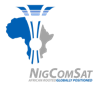 &nbsp;&nbsp; 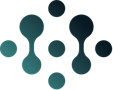

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-5/day-2-forecasting-baselines/4-instructor-only/W5D2-solution.ipynb)

> 🧑🏾‍🏫 **INSTRUCTOR SOLUTION.** Every blank is filled in. Don't share this with participants before the session ends.

# 👵🏾 Week 5 · Day 2: Forecasting Baselines

**Today:** you lock the last 8 weeks of NOC tickets away, forecast them four cheap ways, score every forecast with the same ruler, then find the two-line trick that beats them all.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W5D2-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _same(got, want, tol=1e-6):
    got = np.asarray(got, dtype=float)
    return got.shape == np.asarray(want).shape and bool(np.allclose(got, want, atol=tol))

def _c_a1(x):
    freq, rows, gaps = x
    ok = str(freq).upper() == "W-MON" and rows == 104 and gaps == 0
    return ok, "104 Mondays in a row, 0 gaps. A clean weekly series. 📅", \
        "Every row is a Monday: the weekly code that starts on Monday is \"W-MON\" (in quotes)."

def _c_a2(x):
    return tuple(x) == (96, 8, '2025-11-03'), \
        "96 weeks to learn from, 8 locked away (from 3 Nov 2025). Forecasts are made on 27 Oct, blind. 🔒", \
        "The last 8 weeks: H = 8."

def _c_b1(x):
    s = pd.Series([3.0, 5.0, 9.0])
    return _same(x(s, 4), [9, 9, 9, 9]), \
        "Grandma's forecast: 74 tickets every week (the last training week, 27 Oct). 👵🏾", \
        "The LAST value of the series is position -1: series.iloc[-1]."

def _c_b2(x):
    s = pd.Series(np.arange(1, 105, dtype=float))
    return _same(x(s, 8), np.arange(53, 61, dtype=float)), \
        "It copies 4 Nov – 23 Dec 2024: 42, 42, 44, 42, 53, 51, 52, 54. 📅", \
        "Weekly data, yearly season: one season is 52 weeks, so period=52."

def _c_b3(x):
    s = pd.Series(np.arange(1, 21, dtype=float))
    return _same(x(s, 3), [16.5, 16.5, 16.5]), \
        "The mean of the last 8 training weeks: 77 tickets, held flat. 🧮", \
        "The window is the last 8 weeks: window=8."

def _c_b4(x):
    s = pd.Series([10.0, 20.0])
    return _same(x(s, 2, 0.3), [13.0, 13.0]) and _same(x(s, 1, 0.5), [15.0]), \
        "Each week pulls the level alpha of the way; the rest, (1 - alpha), stays. Level: 75.55 tickets. 🫖", \
        "New level = alpha x new week + (what's left) x old level. What's left of 1 after taking alpha?"

def _c_b5(x):
    s = pd.Series(x)
    want = {'naive': 11.25, 'seasonal_naive': 15.25, 'moving_average': 14.25, 'exp_smoothing': 12.8042}
    ok = all(_near(s[k], v, 0.005) for k, v in want.items())
    return ok, "Naive wins with 11.25 tickets a week. Seasonal naive comes LAST (15.25), on a seasonal series! 🤔", \
        "Compare each forecast with what really happened in the 8 weeks: COMPARE_WITH = actual"

def _c_b6(x):
    return _near(x, 1.347881, 0.0005), \
        "1,581 → 2,131 terminals: the network is 35% bigger than when seasonal naive's weeks were recorded. 📡", \
        "A year ago, in weeks: WEEKS_BACK = 52"

def _c_c1(x):
    want = {(1, 2024): 25.6, (1, 2025): 25.9, (2, 2024): 26.7, (2, 2025): 27.4, (3, 2024): 29.1, (3, 2025): 28.9, (4, 2024): 39.4, (4, 2025): 39.2, (5, 2024): 40.2, (5, 2025): 38.5, (6, 2024): 40.2, (6, 2025): 39.8, (7, 2024): 40.9, (7, 2025): 38.6, (8, 2024): 37.8, (8, 2025): 37.7, (9, 2024): 37.2, (9, 2025): 37.7, (10, 2024): 36.5, (10, 2025): 35.5, (11, 2024): 26.6, (12, 2024): 31.7}
    ok = all(_near(x.loc[m, y], v, 0.051) for (m, y), v in want.items())
    return ok, "Divide by the network and the season repeats: the same month never differs by more than 2.3 per 1,000. ➗", \
        "Divide the tickets by the terminals of the same weeks: DIVIDE_BY = train_terminals"

def _c_c2(x):
    return int(x) == 4, "April: the rain arrives and the rate jumps from about 29 to about 39 per 1,000 terminals. 🌧️", \
        "Find the month where the number jumps by about 10."

def _c_c3(x):
    s = pd.Series([10.0, 20.0, 30.0, 40.0])
    t = pd.Series([100.0, 100.0, 200.0, 200.0])
    return _same(x(s, t, 2, period=4), [20.0, 40.0]), \
        "Last year's rate × today's terminals. For the week of 3 Nov: 56.4 tickets (actual: 53). 🎯", \
        "The rate is tickets per terminal: rate = series / terminals"

def _c_c4(x):
    s = pd.Series(x)
    ok = _near(s["rate_seasonal_naive"], 2.2393, 0.005) and _near(s["naive"], 11.25, 0.005)
    return ok, "2.24 tickets a week: about 5× better than naive, all 8 weeks forecast blind. That's the bar. 🏆", \
        "Forecast all 8 locked weeks: HORIZON = H (or 8)."

def _c_d1(x):
    return _near(x, 7.7734, 0.005), \
        "7.77: the flat average 'beat' all four code-book baselines on these 8 weeks. Skill or luck? Week 6 Day 1 finds out. 🎲", \
        "The flat forecast is the mean of the training weeks: FLAT = train.mean()"

def _c_bonus(x):
    return _near(x, 0.9, 1e-9), \
        "α = 0.9 chases the latest week. On these 8 weeks it scores 11.19, a hair better than naive. Switch to 0.9 now? No: you only know because you peeked. That's expo. 🌶️", \
        "A big alpha gives the newest week a big pull."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4, "B5": _c_b5, "B6": _c_b6,
          "C1": _c_c1, "C2": _c_c2, "C3": _c_c3, "C4": _c_c4, "D1": _c_d1, "BONUS": _c_bonus}
HINTS = {"B1": "Replace the ___ inside the function with the position of the LAST value.",
         "B2": "Replace the ___ with the season length in weeks.",
         "B3": "Replace the ___ with the number of weeks to average.",
         "B4": "Replace the ___ with the share of the OLD level that stays.",
         "C3": "Replace the ___ with tickets divided by terminals.",
         "C1": "DIVIDE_BY = train_terminals (no quotes)."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# Part A: Meet the weeks, lock the last 8 away (10 min) 🔒

### A1 ✍️ Load the weekly tickets
`ops_tickets_weekly` has one row per week: tickets raised at the NOC and the number of active VSAT terminals. Every date is a **Monday**.
Tell pandas the frequency: the weekly code that starts on Monday, as text (in quotes).

In [ ]:
FREQ = "W-MON"

assert FREQ is not None, "✍️ Fill in FREQ first."
tickets = pd.read_csv(data_path("ops_tickets_weekly"), parse_dates=["week_start"], index_col="week_start").asfreq(FREQ)
gaps = int(tickets.isna().sum().sum())
print("weeks:", len(tickets), "· gaps:", gaps, "·", tickets.index[0].date(), "to", tickets.index[-1].date())
display(tickets.head(3))
check("A1", (FREQ, len(tickets), gaps))

### A2 ✍️ Lock the last weeks away
We'll forecast the **last 8 weeks** as if we were standing on the last training week, not knowing them yet. How many weeks is the horizon `H`?

In [ ]:
H = 8

assert H is not None, "✍️ Fill in H first."
assert "tickets" in globals(), "✍️ Finish A1 first, then run this cell."
y = tickets["tickets_raised"]
terminals = tickets["active_vsat_terminals"]
train, actual = y.iloc[:-H], y.iloc[-H:]
train_terminals = terminals.iloc[:-H]
assert train.index.max() < actual.index.min(), "leakage: training overlaps the test"
print("train:", len(train), "weeks, to", train.index[-1].date(), "· test:", len(actual), "weeks, from", actual.index[0].date())
check("A2", (len(train), len(actual), str(actual.index[0].date())))

▶️ Look at the **training** weeks only (the test weeks stay locked). Notice the trend, and the **steps** every April and November.

In [ ]:
assert "train" in globals(), "✍️ Finish A2 first, then run this cell."
fig, ax = plt.subplots()
ax.plot(train.index, train, lw=2.5, label="tickets per week")
ax.axvspan(actual.index[0], actual.index[-1], color="#F5B83D", alpha=.25, label="🔒 locked: the 8 test weeks")
ax2 = ax.twinx()
ax2.plot(train_terminals.index, train_terminals, color="#008C7E", lw=1.5, label="active terminals")
ax2.set_ylabel("terminals")
ax.set_ylabel("tickets")
ax.set_title("NOC tickets grow with the network, and jump every rainy season")
ax.legend(loc="upper left")
plt.show()

---
# Part B: Four baselines, one scorer (25 min) 👵🏾

📖 Each baseline is a tiny function: give it the **training series** and the horizon `h`, it gives back `h` numbers. Each one makes **one assumption** about the world.

▶️ First the scorer you'll use for every forecast today: **MAE**, the mean absolute error. On a typical week, how many tickets were we off by?

In [ ]:
def mae(forecast, actual):
    """Mean absolute error: on a typical week, how many tickets were we off by?"""
    return float(np.mean(np.abs(np.asarray(forecast, float) - np.asarray(actual, float))))

print("example: forecasts 10, 10 vs actual 12, 7 → MAE", mae([10, 10], [12, 7]))

### B1 ✍️ Naive: "same as last week"
Repeat the **last** value of the series. Which position is the last value? (Python counts from the end with minus numbers.)

In [ ]:
def naive(series, h):
    """Grandma's forecast: the last value we saw, repeated h times."""
    return np.full(h, float(series.iloc[-1]))

check("B1", naive)

### B2 ✍️ Seasonal naive: "same week last year"
Copy the same weeks one **season** ago. The data is weekly and the season is yearly: how many weeks in a season? Put it as the default `period`.

In [ ]:
def seasonal_naive(series, h, period=52):
    """The same weeks one season (52 weeks) ago."""
    last_season = series.iloc[-period:].values
    return np.tile(last_season, int(np.ceil(h / period)))[:h].astype(float)

check("B2", seasonal_naive)

### B3 ✍️ Moving average: "the average of the last 8 weeks"
Fill in the default `window`.

In [ ]:
def moving_average(series, h, window=8):
    """The mean of the last `window` weeks, held flat."""
    return np.full(h, float(series.iloc[-window:].mean()))

check("B3", moving_average)

### B4 ✍️ Exponential smoothing: "a running level"
Walk through the weeks, keeping a **level**. Each new week pulls the level `alpha` of the way towards itself; the **rest of the old level stays**. With `alpha = 0.3`, 30% comes from the new week and how much from the old level? Write it with `alpha`.

In [ ]:
def exp_smoothing(series, h, alpha=0.3):
    """Simple exponential smoothing: a running level, each new week pulls it alpha of the way."""
    level = series.iloc[0]
    for v in series.iloc[1:]:
        level = alpha * v + (1 - alpha) * level
    return np.full(h, float(level))

check("B4", exp_smoothing)

▶️ All four forecasts for the 8 locked weeks, next to what really happened. **Now** we unlock the test weeks.

In [ ]:
assert all(SCORE.get(t) for t in ("B1", "B2", "B3", "B4")), "✍️ Get B1 to B4 to ✅ first, then run this cell."
BASELINES = ["naive", "seasonal_naive", "moving_average", "exp_smoothing"]
fc = pd.DataFrame({
    "naive": naive(train, H),
    "seasonal_naive": seasonal_naive(train, H),
    "moving_average": moving_average(train, H),
    "exp_smoothing": exp_smoothing(train, H),
}, index=actual.index)
fc["actual"] = actual.values
display(fc.round(1))

fig, ax = plt.subplots()
ax.plot(y.iloc[-30:], color="black", lw=2.5, label="actual")
for name in BASELINES:
    ax.plot(fc.index, fc[name], "--", lw=2, label=name)
ax.axvspan(actual.index[0], actual.index[-1], color="#F5B83D", alpha=.15)
ax.set_title("Four baselines vs the 8 test weeks")
ax.legend(ncol=5, fontsize=9)
plt.show()

### B5 ✍️ The scoreboard
Score every baseline with `mae(forecast, ...)`. What do you compare each forecast **with**? (A variable, no quotes.)

In [ ]:
COMPARE_WITH = actual

assert COMPARE_WITH is not None, "✍️ Fill in COMPARE_WITH first."
assert "fc" in globals(), "✍️ Run the forecast-table cell above first."
scores = pd.Series({name: mae(fc[name], COMPARE_WITH) for name in BASELINES}).sort_values()
print("MAE, tickets per week (lower is better):")
print(scores.round(2).to_string())
check("B5", scores)

### B6 ✍️ Why did seasonal naive come last?
It copied last year's weeks. How much bigger is the network now than **one year** before the forecast was made? Go back how many weeks?

In [ ]:
WEEKS_BACK = 52

assert WEEKS_BACK is not None, "✍️ Fill in WEEKS_BACK first."
assert "train_terminals" in globals(), "✍️ Finish A2 first, then run this cell."
now = train_terminals.index[-1]
then = now - pd.Timedelta(weeks=WEEKS_BACK)
growth = train_terminals[now] / train_terminals[then]
print(f"{then.date()}: {train_terminals[then]:,} terminals → {now.date()}: {train_terminals[now]:,} terminals = x{growth:.3f}")
check("B6", growth)

> 📖 **What just happened?** Seasonal naive had the right **season** but the wrong **size**: every copied week came from a network about a third smaller. Naive had the right size but the wrong season: it copied 74 tickets, a rainy-season week, into the dry season. Each knows half the story.

---
# Part C: Divide by the size (15 min) ➗

### C1 ✍️ Tickets per 1,000 terminals
Divide each training week's tickets by that week's terminals (×1,000), then average by month for each year. What do you divide by? (A variable, no quotes.)

In [ ]:
DIVIDE_BY = train_terminals

assert DIVIDE_BY is not None, "✍️ Fill in DIVIDE_BY first."
assert not isinstance(DIVIDE_BY, str), "✍️ Use the variable itself, without quotes: DIVIDE_BY = train_terminals"
per_1000 = 1000 * train / DIVIDE_BY
rate_table = per_1000.groupby([per_1000.index.month, per_1000.index.year]).mean().unstack().round(1)
rate_table.index.name, rate_table.columns.name = "month", "year"
display(rate_table)
check("C1", rate_table)

### C2 ✍️ When does the rain arrive?
Read the table. In which month (1–12) does the rate **jump**, in both years?

In [ ]:
RAIN_MONTH = 4

check("C2", RAIN_MONTH)

### C3 ✍️ Rate seasonal naive: Grandma, adjusted for the bigger family
Last year's tickets **per terminal**, times **today's** terminals. Fill in the rate: tickets per terminal, every week.

In [ ]:
def rate_seasonal_naive(series, terminals, h, period=52):
    """Grandma, adjusted for the bigger family: last year's tickets PER TERMINAL x today's terminals."""
    rate = series / terminals
    return rate.iloc[-period:].values[:h] * float(terminals.iloc[-1])

check("C3", rate_seasonal_naive)

### C4 ✍️ Score it on the same 8 weeks
Forecast all the locked weeks at once (blind), then rebuild the scoreboard. How many weeks ahead?

In [ ]:
HORIZON = H

assert HORIZON is not None, "✍️ Fill in HORIZON first."
assert SCORE.get("C3") and "fc" in globals(), "✍️ Get C3 to ✅ and run the forecast-table cell first."
fc["rate_seasonal_naive"] = rate_seasonal_naive(train, train_terminals, HORIZON)
scores_all = pd.Series({name: mae(fc[name], actual) for name in fc.columns if name != "actual"}).sort_values()
print(scores_all.round(2).to_string())

fig, ax = plt.subplots()
ax.plot(y.iloc[-30:], color="black", lw=2.5, label="actual")
ax.plot(fc.index, fc["naive"], "--", lw=2, label="naive")
ax.plot(fc.index, fc["rate_seasonal_naive"], "--", lw=3, color="#1E9E5A", label="rate seasonal naive")
ax.axvspan(actual.index[0], actual.index[-1], color="#F5B83D", alpha=.15)
ax.legend()
ax.set_title("Divide by the size: the rate forecast follows the drop AND the growth")
plt.show()
check("C4", scores_all)

> 📖 **The bar is set.** About 5× smaller error than naive, with nothing fitted and nothing tuned. Every fancier model from now on must beat **this** number, on the same weeks, with the same scorer.

---
# Part D: One split can lie (5 min) 🎲

### D1 ✍️ The flat training average
The code book calls a flat average "the wrong baseline" for a growing series. Try it anyway: say the **mean of the training weeks** every week.

In [ ]:
FLAT = train.mean()

assert FLAT is not None, "✍️ Fill in FLAT first."
assert "fc" in globals(), "✍️ Run the forecast-table cell first."
fc["training_mean"] = np.full(H, float(FLAT))
flat_mae = mae(fc["training_mean"], actual)
print(f"flat average {float(FLAT):.1f} every week → MAE {flat_mae:.2f}")
check("D1", flat_mae)

> 📖 **Skill or luck?** The flat average "beat" all four code-book baselines on these 8 weeks: the dry-season drop and the network's growth happened to cancel out. One split is one result. **Week 6 · Day 1** (backtesting) checks every method on dozens of different 8-week stretches.

---
## 🌶️ Pepper task: change α, and spot the expo trap
▶️ The cell runs exponential smoothing with three values of `alpha`. ✍️ Which value makes the forecast **follow the latest week closely**?

⚠️ The cell also prints each one's MAE on the test weeks. **Don't** pick `alpha` from those numbers: choosing a setting by looking at the test answers is expo (Week 5 · Day 1). Pick your settings from the training weeks, or keep the default.

In [ ]:
assert "train" in globals(), "✍️ Finish A2 first, then run this cell."
print(f"last training week: {train.iloc[-1]}")
for a in (0.1, 0.3, 0.9):
    f = exp_smoothing(train, H, alpha=a)
    print(f"alpha {a}: level {f[0]:.2f} · MAE on the test weeks {mae(f, actual):.2f}  (look, but don't choose with this!)")

FOLLOWS_LATEST = 0.9

check("BONUS", FOLLOWS_LATEST)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- A **forecast** is a guess about the future made only from the past. Lock the test weeks away and forecast them **blind**.
- **Baselines** are the cheapest forecasts: naive (last week), seasonal naive (same week last year), moving average, exponential smoothing. Each makes one assumption.
- **MAE** is the typical miss in the data's own unit. Naive scored 11.25: "off by about 11 tickets on a typical week".
- Seasonal naive came last (15.25) on a seasonal series because it copied a network 35% smaller. Naive "won" by copying the wrong season.
- **Divide by the size:** tickets per terminal repeat every year. Last year's rate × today's terminals scored **2.24**. That's the bar every later model must beat.
- **One split can lie:** even a flat average scored 7.77 here. Week 6 · Day 1 tests on many splits.

**Next time:** *Regression forecasts + honest ranges*: "I'm on my way" vs "30 to 90 minutes, Third Mainland Bridge permitting". 🚗

<sub>Data: synthetic teaching dataset from the original Week 6 code book (`Time-series/week-06`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>